# Задание 4.9

Отрезок $[0;1]$ случайным образом делится на 3 части. Найти вероятность того, что из полученных отрезков можно сложить треугольник и этот треугольник будет остроугольным. Постройте график зависимости относительной частоты $\hat p(A)=\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N=150\,000$ и приведите оценку вероятности $\hat p(A)=\dfrac{N_A}{N}$ для $N=150\,000$. Найдите аналитическое решение для вероятности.

**Ответ:** $\mathbb P(A)=3\ln2-2\approx0{,}0794415417$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**1) Пространство элементарных исходов.** На отрезок наудачу бросают две точки; $x$ — левая, $y$ — правая:

$$
\Omega=\{(x,y):\ 0\le x\le y\le1\},\qquad \mu(\Omega)=\frac12 .
$$

Длины частей: $a=x$, $\ b=y-x$, $\ c=1-y$, $\ a+b+c=1$.

**2) Треугольник существует** ⇔ каждая сторона меньше суммы двух других ⇔ каждая сторона меньше $\frac12$:

$$
x\le\frac12,\qquad y\ge\frac12,\qquad y\le x+\frac12 .
$$

Это треугольник площади $\frac18$ (вероятность получить треугольник равна $\frac14$).

**3) Остроугольность.** По теореме косинусов угол против стороны $c$ острый ⇔ $c^2<a^2+b^2$. Поэтому

$$
A:\ \begin{cases}
x\le y,\ \ y\ge\frac12,\ \ x\le\frac12,\ \ y\le x+\frac12,\\[2pt]
x^2+(1-y)^2\ge(y-x)^2,\\
x^2+(y-x)^2\ge(1-y)^2,\\
(y-x)^2+(1-y)^2\ge x^2 .
\end{cases}
$$

**4) Площадь.** Перейдём к переменным $(a,b)=(x,\,y-x)$ (якобиан равен 1), $c=1-a-b$. Угол против $c$ тупой ⇔ $(1-a-b)^2>a^2+b^2$ ⇔ $b<\dfrac{1-2a}{2(1-a)}=1-\dfrac{1}{2(1-a)}$. Внутри треугольника $\{a,b<\frac12,\ a+b>\frac12\}$ эта часть имеет площадь

$$
S_c=\int_0^{1/2}\Big[\Big(1-\frac{1}{2(1-a)}\Big)-\Big(\frac12-a\Big)\Big]da=\frac14+\frac18-\frac{\ln2}{2}=\frac38-\frac{\ln2}{2}.
$$

Тупым может быть только один угол, и по симметрии площади $S_a=S_b=S_c$. Значит,

$$
\mu(A)=\frac18-3\Big(\frac38-\frac{\ln2}{2}\Big)=\frac32\ln2-1,\qquad
\mathbb P(A)=\frac{\mu(A)}{\mu(\Omega)}=\frac{\frac32\ln2-1}{\frac12}=3\ln2-2\approx0{,}0794415 .
$$

Область $A$ на плоскости $(x,y)$ — криволинейный треугольник, ограниченный тремя дугами гипербол (красная область на рисунке).

S_c = 3/8 - log(2)/2,  μ(A) = -1 + 3*log(2)/2,  P(A) = -2 + log(8) ≈ 0.0794415417


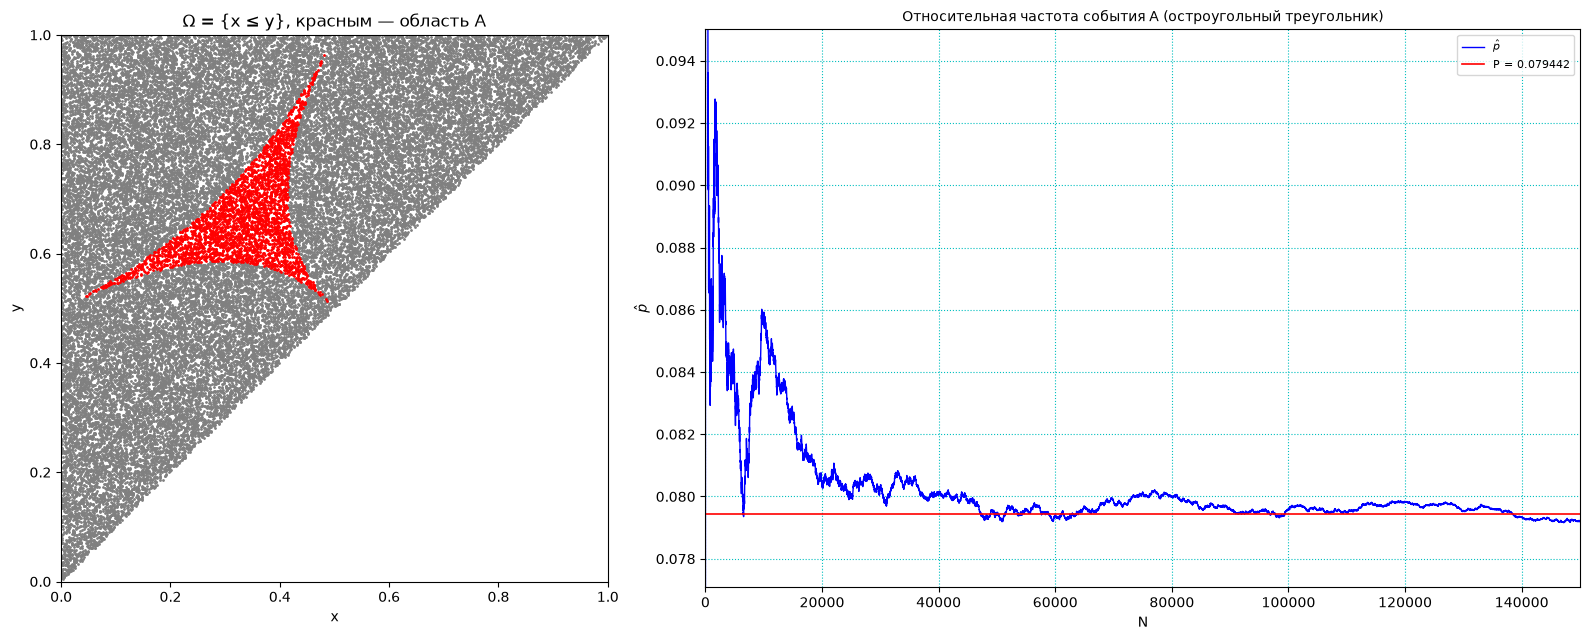

Оценка p̂ = N_A/N = 11878/150000 = 0.079187;  P(A) = 3 ln 2 - 2 = 0.079442


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Аналитическое решение: проверка площадей в sympy ----------
a_ = sp.symbols("a", positive=True)
S_c = sp.integrate((1 - 1/(2*(1 - a_))) - (sp.Rational(1, 2) - a_), (a_, 0, sp.Rational(1, 2)))
mu_A = sp.Rational(1, 8) - 3*S_c
P_exact = sp.simplify(mu_A / sp.Rational(1, 2))
print(f"S_c = {sp.simplify(S_c)},  μ(A) = {sp.simplify(mu_A)},  P(A) = {P_exact} ≈ {float(P_exact):.10f}")


def acute(x, y):
    """Проверка: из частей x, y - x, 1 - y складывается остроугольный треугольник."""
    a, b, c = x, y - x, 1 - y
    return (a**2 + b**2 > c**2) & (a**2 + c**2 > b**2) & (b**2 + c**2 > a**2)   # все углы острые (влечёт и неравенство треугольника)


# ---------- Моделирование: две случайные точки на [0, 1] ----------
N = 150_000
u = rng.random((N, 2))
x, y = u.min(axis=1), u.max(axis=1)        # левая и правая точки разбиения
hits = acute(x, y)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
s = slice(0, 40_000)
axes[0].scatter(x[s][~hits[s]], y[s][~hits[s]], s=1, c="gray", rasterized=True)
axes[0].scatter(x[s][hits[s]], y[s][hits[s]], s=1, c="red", rasterized=True)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1); axes[0].set_aspect("equal")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y"); axes[0].set_title("Ω = {x ≤ y}, красным — область A")
ph = plot_freq(axes[1], hits, float(P_exact), "Относительная частота события A (остроугольный треугольник)")
fig.tight_layout()
plt.show()

print(f"Оценка p̂ = N_A/N = {hits.sum()}/{N} = {ph:.6f};  P(A) = 3 ln 2 - 2 = {3*np.log(2) - 2:.6f}")